# 01 · Límites municipales y parques solares
**Datos tipo ÁREA:** los 30 municipios del Magdalena.
**Datos tipo PUNTO:** los parques solares de `parques_magdalena.csv`.

Por defecto los límites se descargan de **geoBoundaries** (libre, sin registro). Si prefieres la fuente oficial, descarga el **Marco Geoestadístico Nacional (MGN) del DANE** desde https://geoportal.dane.gov.co y pon la ruta del shapefile de municipios en `MGN_LOCAL`.

In [1]:
# ▶ CELDA DE PREPARACIÓN — ejecútala siempre de primera
import os, sys, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    # En Colab los archivos se guardan en tu Google Drive para no perderlos
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = Path("/content/drive/MyDrive/scm_magdalena")   # cámbiala si quieres
    CARPETA.mkdir(parents=True, exist_ok=True)
    os.chdir(CARPETA)
    PAQUETES = ["numpy", "scipy", "pandas", "xarray", "dask", "netCDF4", "h5netcdf", "s3fs", "pyproj", "shapely", "geopandas", "rasterio", "pvlib", "pydataxm", "libpysal", "esda", "matplotlib"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PAQUETES], check=True)

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("Carpeta de trabajo:", os.getcwd())
assert Path("config.py").exists(), "No encuentro config.py: ejecuta primero el notebook 00 en esta misma carpeta"

Carpeta de trabajo: c:\Users\User\Desktop\Unal\Analisis Geoespacial\notebooks_scm_magdalena


In [2]:
import json, urllib.request
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import config as C

MGN_LOCAL = None    # p. ej. r"C:\datos\MGN_MPIO_POLITICO.shp"

## 1. Municipios del Magdalena

In [3]:
def descargar_geoboundaries(nivel):
    api = f"https://www.geoboundaries.org/api/current/gbOpen/COL/{nivel}/"
    with urllib.request.urlopen(api) as r:
        meta = json.load(r)
    return gpd.read_file(meta["gjDownloadURL"])

if MGN_LOCAL:
    mpios = gpd.read_file(MGN_LOCAL)
    col = [c for c in mpios.columns if "DPTO" in c.upper() and "CCDGO" in c.upper()][0]
    mpios = mpios[mpios[col].astype(str) == C.COD_DANE].to_crs(4326)
    region = mpios.dissolve()
else:
    dptos = descargar_geoboundaries("ADM1")
    region = dptos[dptos["shapeName"].str.contains(C.REGION, case=False)].to_crs(4326)
    print("Departamento encontrado:", region["shapeName"].tolist())
    mpios_col = descargar_geoboundaries("ADM2").to_crs(4326)
    centroides = mpios_col.copy()
    centroides["geometry"] = centroides.representative_point()
    dentro = gpd.sjoin(centroides, region[["geometry"]], predicate="within")
    mpios = mpios_col.loc[dentro.index]

region.to_file(C.PROC / "region.gpkg", driver="GPKG")
mpios.to_file(C.PROC / "municipios.gpkg", driver="GPKG")
print(f"{len(mpios)} municipios guardados (el Magdalena tiene 30)")

Departamento encontrado: ['Magdalena']
30 municipios guardados (el Magdalena tiene 30)


## 2. Parques solares (capa de puntos)

In [4]:
p = pd.read_csv(C.ARCHIVO_PARQUES)
parques = gpd.GeoDataFrame(p, geometry=gpd.points_from_xy(p.lon, p.lat), crs=4326)
parques.to_file(C.PROC / "parques.gpkg", driver="GPKG")
parques[["nombre", "municipio", "capacidad_mw", "estado"]]

,nombre,municipio,capacidad_mw,estado
0,Parque Solar Fundación (Enel),Fundación / Pivijay,100.0,Operación comercial desde 2024 (despacho centr...
1,Caimán Cienaguero,Ciénaga,14.3,Operación comercial desde ene-2024


## 3. Mapa de control

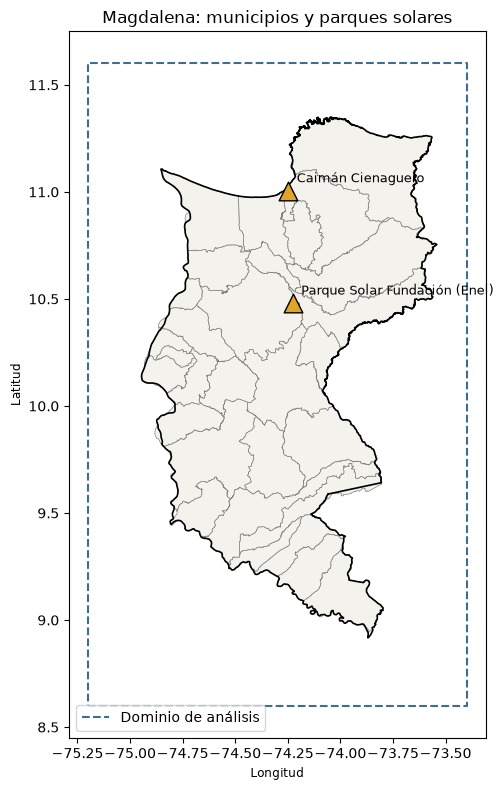

In [5]:
fig, ax = plt.subplots(figsize=(7, 8))
mpios.plot(ax=ax, color="#F4F2EC", edgecolor="0.5", linewidth=0.5)
region.boundary.plot(ax=ax, color="k", linewidth=1.2)
parques.plot(ax=ax, color="#E0A526", edgecolor="k", marker="^", markersize=180, zorder=3)
for _, r in parques.iterrows():
    ax.annotate(r["nombre"], (r.lon, r.lat), xytext=(6, 6), textcoords="offset points", fontsize=9)
la0, la1, lo0, lo1 = C.DOM_ANALISIS
ax.plot([lo0, lo1, lo1, lo0, lo0], [la0, la0, la1, la1, la0], "--", color="#3D6E8F", label="Dominio de análisis")
ax.legend(loc="lower left"); ax.set_title("Magdalena: municipios y parques solares")
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
plt.tight_layout(); plt.savefig(C.OUT / "mapa_area_estudio.png", dpi=150); plt.show()

✅ Si el mapa muestra el Magdalena con sus municipios y los parques dentro, sigue con el notebook **02**.